# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from sklearn.svm import LinearSVC, SVC

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [2]:
data1 = loadmat('./data/ejer_1_data1.mat')


In [3]:
print(data1.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])


In [4]:
data1["X"] # Vemos a ver cuantos elementos/columnas hay dentro de la X (spoiler: son 2)

array([[1.9643  , 4.5957  ],
       [2.2753  , 3.8589  ],
       [2.9781  , 4.5651  ],
       [2.932   , 3.5519  ],
       [3.5772  , 2.856   ],
       [4.015   , 3.1937  ],
       [3.3814  , 3.4291  ],
       [3.9113  , 4.1761  ],
       [2.7822  , 4.0431  ],
       [2.5518  , 4.6162  ],
       [3.3698  , 3.9101  ],
       [3.1048  , 3.0709  ],
       [1.9182  , 4.0534  ],
       [2.2638  , 4.3706  ],
       [2.6555  , 3.5008  ],
       [3.1855  , 4.2888  ],
       [3.6579  , 3.8692  ],
       [3.9113  , 3.4291  ],
       [3.6002  , 3.1221  ],
       [3.0357  , 3.3165  ],
       [1.5841  , 3.3575  ],
       [2.0103  , 3.2039  ],
       [1.9527  , 2.7843  ],
       [2.2753  , 2.7127  ],
       [2.3099  , 2.9584  ],
       [2.8283  , 2.6309  ],
       [3.0473  , 2.2931  ],
       [2.4827  , 2.0373  ],
       [2.5057  , 2.3853  ],
       [1.8721  , 2.0577  ],
       [2.0103  , 2.3546  ],
       [1.2269  , 2.3239  ],
       [1.8951  , 2.9174  ],
       [1.561   , 3.0709  ],
       [1.5495

#### 3. Create a DataFrame with the features and target

In [5]:
df1 = pd.DataFrame(data1['X'], columns=['x1', 'x2'])
df1['y'] = data1['y']

df1.head()

,x1,x2,y
0,1.9643,4.5957,1
1,2.2753,3.8589,1
2,2.9781,4.5651,1
3,2.9320,3.5519,1
4,3.5772,2.8560,1


In [6]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      51 non-null     float64
 1   x2      51 non-null     float64
 2   y       51 non-null     uint8  
dtypes: float64(2), uint8(1)
memory usage: 999.0 bytes


In [7]:
df1.describe()

,x1,x2,y
count,51.000000,51.000000,51.000000
mean,2.268780,3.132512,0.411765
std,0.928531,0.753256,0.497050
min,0.086405,1.617700,0.000000
25%,1.572550,2.636000,0.000000
50%,2.275300,3.070900,0.000000
75%,2.955050,3.531400,1.000000
max,4.015000,4.616200,1.000000


#### 4. Plot a scatterplot with the data

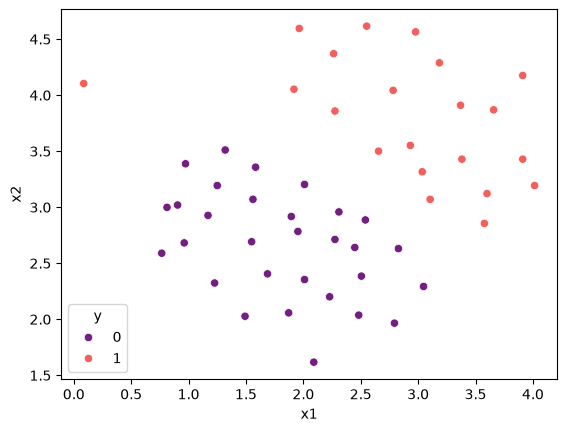

In [8]:
sns.scatterplot(data=df1, x='x1', y='x2', hue='y', palette='magma');

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [9]:
svc1 =LinearSVC(C=1, loss='hinge', max_iter=10000)

#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [11]:
X1 = df1[['x1', 'x2']]
y1 = df1['y']


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", svc1)
])

svm_clf.fit(X1, y1)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('linear_svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [14]:
print("Score con C=1:", svm_clf.score(X1, y1))

Score con C=1: 0.9803921568627451


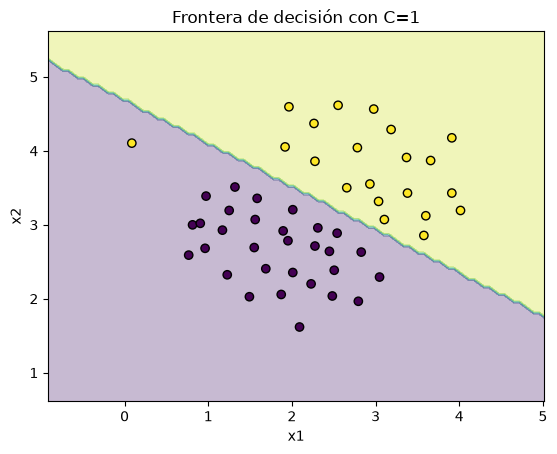

In [17]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

# Dibuja las zonas de clasificación y los puntos reales encima
DecisionBoundaryDisplay.from_estimator(svm_clf, X1, response_method="predict", alpha=0.3)
plt.scatter(X1['x1'], X1['x2'], c=y1, edgecolors='k')
plt.title("Frontera de decisión con C=1")
plt.show()

> Vemos que clasifica mal el outlier --> El modelo obtiene un score de 0.9804 (50 aciertos de 51 puntos). Esto demuestra que, al usar un parámetro de regularización bajo (C=1), el modelo prefiere mantener un margen amplio y tolera clasificar mal el único outlier en lugar de deformar la frontera de decisión para incluirlo.


It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [33]:
svm_clf2 = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", LinearSVC(C=15, loss='hinge', max_iter=10000))
])

svm_clf2.fit(X1, y1)

print("Score con C= 15:", svm_clf2.score(X1, y1))

Score con C= 15: 1.0


In [36]:
svm_clf3 = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", LinearSVC(C=14, loss='hinge', max_iter=10000))
])

svm_clf3.fit(X1, y1)

print("Score con C= 14:", svm_clf3.score(X1, y1))

Score con C= 14: 0.9803921568627451


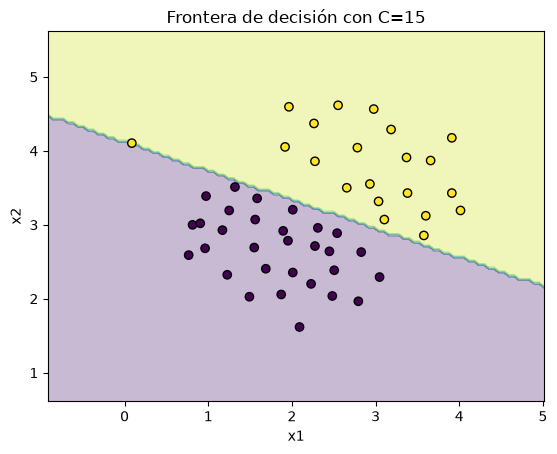

In [38]:
DecisionBoundaryDisplay.from_estimator(svm_clf2, X1, response_method="predict", alpha=0.3)
plt.scatter(X1['x1'], X1['x2'], c=y1, edgecolors='k')
plt.title("Frontera de decisión con C=15")
plt.show()

This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

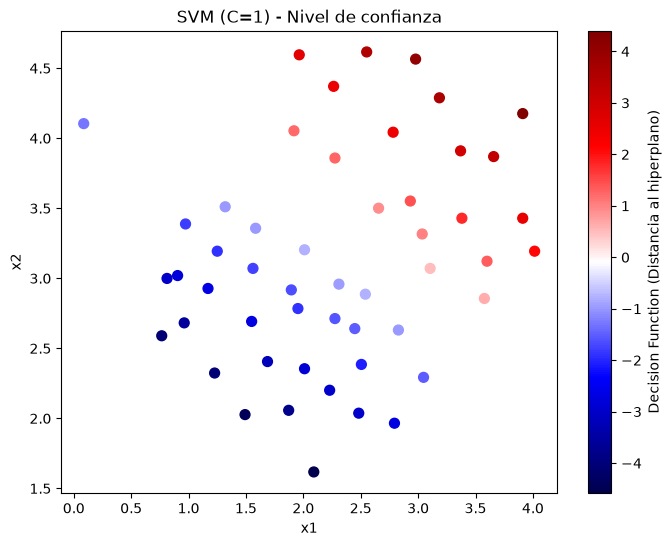

In [40]:
df1['SVM_1_Confidence'] = svm_clf.decision_function(X1)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df1['x1'], df1['x2'], c=df1['SVM_1_Confidence'], cmap='seismic', s=50)
plt.colorbar(scatter, label='Decision Function (Distancia al hiperplano)')
plt.title('SVM (C=1) - Nivel de confianza')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

#### 9. Do the same with the second model

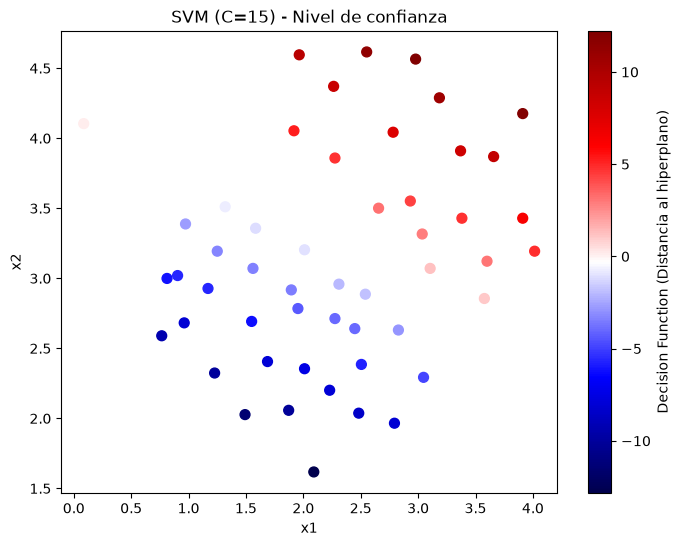

In [41]:
df1['SVM_2_Confidence'] = svm_clf2.decision_function(X1)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df1['x1'], df1['x2'], c=df1['SVM_2_Confidence'], cmap='seismic', s=50)
plt.colorbar(scatter, label='Decision Function (Distancia al hiperplano)')
plt.title('SVM (C=15) - Nivel de confianza')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [43]:
data2 = loadmat('./data/ejer_1_data2.mat')

#### 2. Create a DataFrame with the features and target

In [45]:
print(data2.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])


In [46]:
data2["X"] # Vemos a ver cuantos elementos/columnas hay dentro de la X (spoiler: son 2)

array([[0.107143 , 0.60307  ],
       [0.093318 , 0.649854 ],
       [0.0979263, 0.705409 ],
       ...,
       [0.975806 , 0.439474 ],
       [0.989631 , 0.425439 ],
       [0.996544 , 0.414912 ]], shape=(863, 2))

In [44]:
df2 = pd.DataFrame(data2['X'], columns=['x1', 'x2'])
df2['y'] = data2['y']

df2.head()

,x1,x2,y
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1


#### 3. Plot a scatterplot with the data

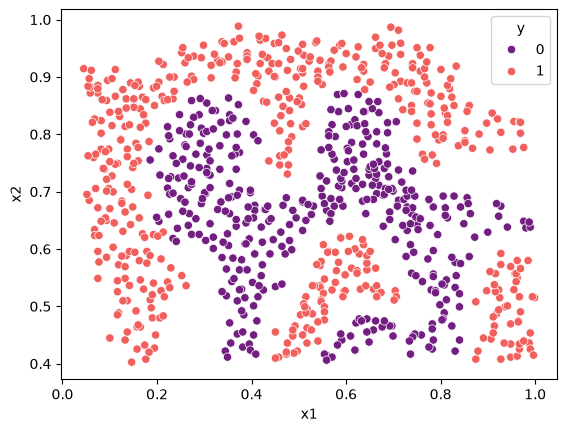

In [47]:
sns.scatterplot(data=df2, x='x1', y='x2', hue='y', palette='magma');

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [51]:
svc_rbf_hyper = SVC(C=100, gamma=10, probability=True)

#### 5. Fit the classifier and get the score

In [49]:
X2 = df2[['x1', 'x2']]
y2 = df2['y']


In [52]:
svc_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("rbf", svc_rbf_hyper)
])

svc_rbf.fit(X2, y2)

c:\Users\ngo1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('rbf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

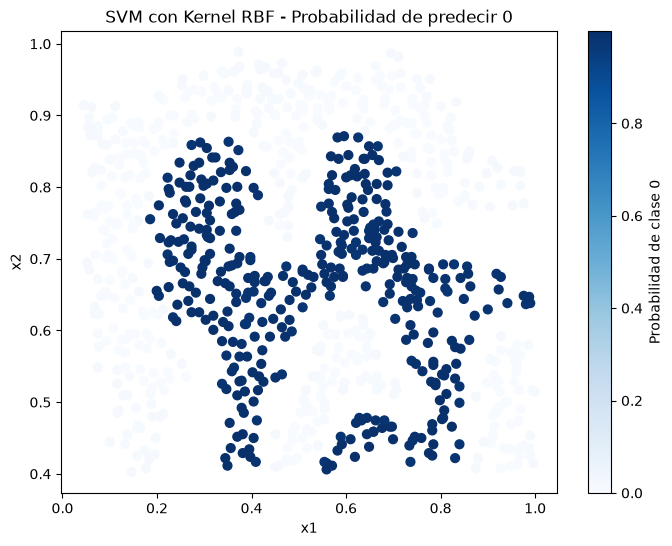

In [57]:
df2['Prob_0'] = svc_rbf.predict_proba(X2)[:, 0]

plt.figure(figsize=(8, 6))

scatter = plt.scatter(df2['x1'], df2['x2'], c=df2['Prob_0'], cmap='Blues', s=40)
plt.colorbar(scatter, label='Probabilidad de clase 0')
plt.title('SVM con Kernel RBF - Probabilidad de predecir 0')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()